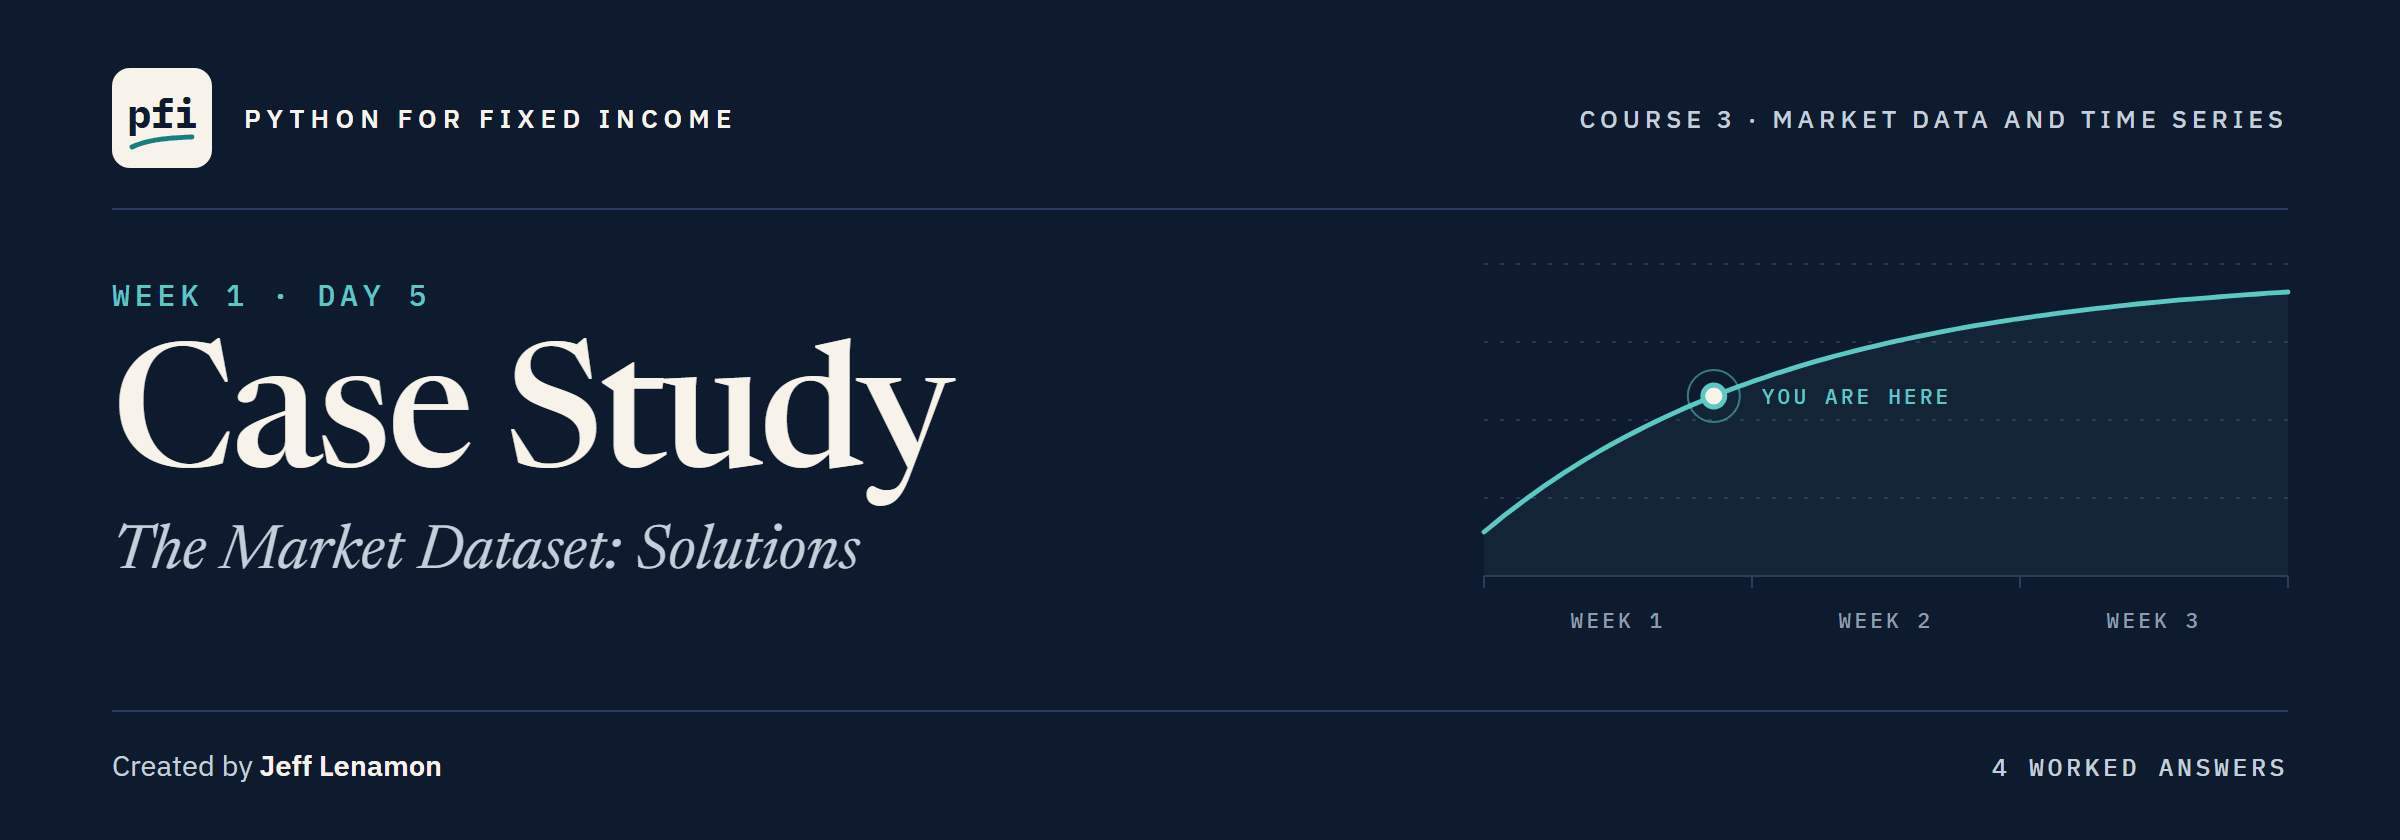

# Case Study: The Market Dataset: Solutions

Week 1, Day 5. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day5/05_case_study_the_market_dataset_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the two files and the dataset, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 05 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(5, after=5)

Work folder pfi_course3_05_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 05 left it, 5 commits, tagged week1


In [2]:
import importlib

import pandas as pd

import marketdata as md

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
TENORS = ['3 Mo', '2 Yr', '5 Yr', '10 Yr', '30 Yr']
SPREADS = ['ig_spread_bp', 'hy_spread_bp']
columns = {tenor: treasury[tenor] for tenor in TENORS}
columns['ig_spread_bp'] = spreads['ig_spread_bp']
columns['hy_spread_bp'] = spreads['hy_spread_bp']
dataset = md.align(columns, how='inner')
print(f'{len(dataset):,} rows, {dataset.shape[1]} columns')

2,940 rows, 7 columns


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
# the 5.9 columns plus two tenors that also run the whole file
ex1_columns = {tenor: treasury[tenor] for tenor in TENORS + ['7 Yr', '20 Yr']}
ex1_columns['ig_spread_bp'] = spreads['ig_spread_bp']
ex1_columns['hy_spread_bp'] = spreads['hy_spread_bp']
ex1_dataset = md.align(ex1_columns, how='inner')
assert ex1_dataset.notna().all().all() and len(ex1_dataset) == len(treasury)
ex1_shape = ex1_dataset.shape
ex1_seven = ex1_dataset.loc['2026-09-30', '7 Yr']
print(ex1_shape, ex1_seven)

(2940, 9) 5.19


Both tenors have a value on every row; a late tenor such as the 4 Mo would fail the no-blank check.

In [5]:
check('Exercise 1 shape', ex1_shape, (2940, 9))
check('Exercise 1 the 7 Yr on 2026-09-30', ex1_seven, 5.19)

Exercise 1 shape: correct
Exercise 1 the 7 Yr on 2026-09-30: correct


### Exercise 2

In [6]:
# the gap in bp on every date; both spreads are synthetic
ex2_gap = dataset['hy_spread_bp'] - dataset['ig_spread_bp']
ex2_all_above = (ex2_gap > 0).all()
ex2_narrowest = ex2_gap.min()
print(f'Above on every row: {ex2_all_above}; narrowest {ex2_narrowest:.1f} bp on '
      f'{ex2_gap.idxmin().date()}')

Above on every row: True; narrowest 91.5 bp on 2019-06-10


A check of the invented file, not a claim about any real market.

In [7]:
check('Exercise 2 above on every row', ex2_all_above, True)
check('Exercise 2 narrowest gap', ex2_narrowest, 91.5)

Exercise 2 above on every row: correct
Exercise 2 narrowest gap: correct


### Exercise 3

In [8]:
%%writefile -a marketdata.py


def dataset_checks(frame: pd.DataFrame) -> None:
    """Stop at the first failed check of a daily market dataset; return None when every check passes.

    Units: none; checks only. Convention: week 1's checks, in this order: a DatetimeIndex of unique ascending
    dates; no Saturday or Sunday; no missing value in any column; no run of 5 or more identical values in a
    spread column (a column whose name ends in _bp). A repeated yield is reported elsewhere, not stopped here.
    Raises ValueError naming the first check that failed.
    """
    _check_index(frame.index, "frame")
    # Saturday is day 5 and Sunday day 6 in pandas' count, which starts at Monday = 0
    weekend = frame.index[frame.index.dayofweek >= 5]
    if len(weekend) > 0:
        raise ValueError(f"frame has {len(weekend)} weekend dates, the first {weekend[0].date()}")
    # the first column with a gap, if any
    gaps = frame.columns[frame.isna().any()]
    if len(gaps) > 0:
        raise ValueError(f"column {gaps[0]!r} has {int(frame[gaps[0]].isna().sum())} missing values")
    for column in [name for name in frame.columns if str(name).endswith("_bp")]:
        runs = stale_runs(frame[column], min_length=5)
        if len(runs) > 0:
            raise ValueError(f"column {column!r} has a stale run of {runs['length'].iloc[0]} "
                             f"from {runs['start'].iloc[0].date()}")

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


def test_dataset_checks_stop_on_first_failure():
    # three market days of the 10 Yr (percent) with a made-up spread column (bp)
    dates = pd.DatetimeIndex(["2026-09-28", "2026-09-29", "2026-09-30"], name="date")
    good = pd.DataFrame({"10 Yr": [5.24, 5.26, 5.29], "ig_spread_bp": [98.1, 98.5, 98.8]}, index=dates)
    assert md.dataset_checks(good) is None
    # Saturday 2026-10-03 in place of the last date
    weekend = good.set_axis(pd.DatetimeIndex(["2026-09-28", "2026-09-29", "2026-10-03"], name="date"))
    with pytest.raises(ValueError, match="weekend"):
        md.dataset_checks(weekend)
    gap = good.copy()
    gap.iloc[1, 0] = float("nan")
    with pytest.raises(ValueError, match="missing"):
        md.dataset_checks(gap)
    # five identical spreads in a row
    five = pd.DataFrame({"ig_spread_bp": [98.8] * 5}, index=pd.bdate_range("2026-09-21", periods=5, name="date"))
    with pytest.raises(ValueError, match="stale"):
        md.dataset_checks(five)

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................                                                    [100%]
21 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_passes = md.dataset_checks(dataset) is None
shifted = dataset.copy()
# an .index = line replaces the row labels: every date one day earlier
shifted.index = dataset.index - pd.Timedelta(days=1)
try:
    md.dataset_checks(shifted)
    ex3_caught = False
except ValueError as error:
    print(f'ValueError: {error}')
    ex3_caught = 'weekend' in str(error)

ValueError: frame has 538 weekend dates, the first 2015-01-04


Moved back a day, every Monday became a Sunday; the date checks run first because the others rely on them.

In [12]:
check('Exercise 3 the dataset passes', ex3_passes, True)
check('Exercise 3 the shifted dataset is caught', ex3_caught, True)

Exercise 3 the dataset passes: correct
Exercise 3 the shifted dataset is caught: correct


### Exercise 4: AI check

The bug: "to be safe", the function gives the dates a time zone they never had.
Midnight UTC is 8 or 7 in the evening of the day before in New York, so `normalize()` keeps the day before: every date moves back one.
Both files move together, so each spread still sits beside its own curve row, but the row labelled 2026-09-30 holds 2026-10-01's values.
The fix: leave the dates as the files hold them.

In [13]:
def build_market_dataset(curve_path, spreads_path, tenors):
    """Build the daily market dataset from the Treasury file and the synthetic spreads.

    Units: yields in percent and spreads in bp, as the files hold them.
    Convention: one row per date of the Treasury file, each the US business date the values are
    published for, with the spreads of that same date beside the curve. Dates are calendar dates
    with no time and no time zone: nothing is localized or converted.
    """
    curve = pd.read_csv(curve_path, parse_dates=['date'], index_col='date',
                        float_precision='round_trip')[tenors]
    spreads = pd.read_csv(spreads_path, parse_dates=['date'], index_col='date',
                          float_precision='round_trip')
    # the fix: the dates stay exactly as the files hold them
    return curve.join(spreads, how='inner')

In [14]:
dataset_ai = build_market_dataset('treasury_par_yields.csv', 'course3_synthetic_spreads.csv',
                                  TENORS)
file_dates = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'])['date']
assert dataset_ai.loc['2026-09-30', '10 Yr'] == 5.29, "2026-09-30 does not hold that day's 10 Yr"
assert dataset_ai.loc['2026-09-30', 'ig_spread_bp'] == 98.8, "2026-09-30's spread is another day's"
assert dataset_ai.index.equals(pd.DatetimeIndex(file_dates)), "the dates are not the file's"
print("Every date is the file's, and 2026-09-30 holds 5.29 percent and 98.8 bp")
ex4_ten = dataset_ai.loc['2026-09-30', '10 Yr']
ex4_ig = dataset_ai.loc['2026-09-30', 'ig_spread_bp']
ex4_same_dates = dataset_ai.index.equals(treasury.index)

Every date is the file's, and 2026-09-30 holds 5.29 percent and 98.8 bp


A known value on a known date catches any shift of the calendar, whatever causes it.

In [15]:
check('Exercise 4 the 10 Yr on 2026-09-30', ex4_ten, 5.29)
check('Exercise 4 the spread on 2026-09-30', ex4_ig, 98.8)
check('Exercise 4 the same dates', ex4_same_dates, True)

Exercise 4 the 10 Yr on 2026-09-30: correct
Exercise 4 the spread on 2026-09-30: correct
Exercise 4 the same dates: correct


[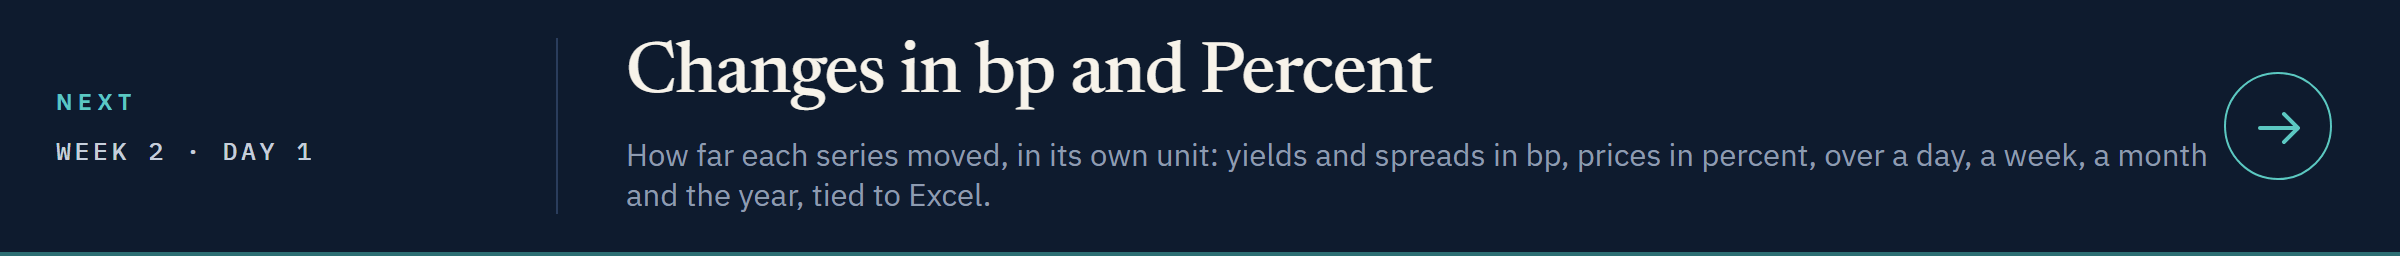](../../week2/day1/06_changes_in_bp_and_percent.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day1/06_changes_in_bp_and_percent.ipynb)